In [50]:
import cobra
import pandas as pd
import matplotlib.pyplot as plt

In [51]:
model = cobra.io.read_sbml_model("../../../model/mit1002-gem.xml")

In [52]:
# Check that the medium has no carbon in it
for met in model.medium:
    print(f"{met}: {model.metabolites.get_by_id(met[3:-3] + '_c0').name}")

EX_cpd00244_e0: Ni2+
EX_cpd00048_e0: Sulfate
EX_cpd00254_e0: Mg
EX_cpd00001_e0: H2O
EX_cpd00063_e0: Ca2+
EX_cpd00067_e0: H+
EX_cpd00034_e0: Zn2+
EX_cpd00013_e0: NH3
EX_cpd00099_e0: Cl-
EX_cpd00305_e0: Thiamin
EX_cpd00205_e0: K+
EX_cpd10516_e0: fe3
EX_cpd00058_e0: Cu2+
EX_cpd00009_e0: Phosphate
EX_cpd00007_e0: O2
EX_cpd00030_e0: Mn2+
EX_cpd00971_e0: Na+
EX_cpd00149_e0: Co2+
EX_cpd00209_e0: Nitrate


In [53]:
SUBSTRATES = {
    "glucose":       "EX_cpd00027_e0",
    "acetate":       "EX_cpd00029_e0",
    "glycerol":      "EX_cpd00100_e0",
    "leucine":       "EX_cpd00107_e0",
    "hexadecanoate": "EX_cpd00214_e0",   # palmitate, a fatty acid
    "ethanol":       "EX_cpd00363_e0",
}
CARBON_UPTAKE = 60        # mmol C / gDW / h, the same for every substrate
O2_EX  = "EX_cpd00007_e0"
CO2_EX = "EX_cpd00011_e0"
BIOMASS_C = 42.94

In [54]:
def degree_of_reduction(met):
    e = met.elements
    electrons = 4*e.get("C", 0) + 1*e.get("H", 0) - 2*e.get("O", 0) - 3*e.get("N", 0)
    electrons -= met.charge          # a negative charge means one extra electron
    return electrons / e["C"]        # per C-mol

for name, ex_id in SUBSTRATES.items():
    met = list(model.reactions.get_by_id(ex_id).metabolites)[0]
    print(f"{name:15s} {met.formula:12s} charge={met.charge:+d}  gamma={degree_of_reduction(met):.2f}")

glucose         C6H12O6      charge=+0  gamma=4.00
acetate         C2H3O2       charge=-1  gamma=4.00
glycerol        C3H8O3       charge=+0  gamma=4.67
leucine         C6H13NO2     charge=+0  gamma=5.00
hexadecanoate   C16H31O2     charge=-1  gamma=5.75
ethanol         C2H6O        charge=+0  gamma=6.00


In [55]:
# Add a free ATP reaction, switched off
atp = model.metabolites.get_by_id("cpd00002_c0")
adp = model.metabolites.get_by_id("cpd00008_c0")
pi  = model.metabolites.get_by_id("cpd00009_c0")
h   = model.metabolites.get_by_id("cpd00067_c0")
h2o = model.metabolites.get_by_id("cpd00001_c0")

free_atp = cobra.Reaction("FREE_ATP")
free_atp.add_metabolites({adp: -1, pi: -1, h: -1, atp: 1, h2o: 1})
free_atp.bounds = (0, 0)             # off by default
model.add_reactions([free_atp])
print(free_atp.build_reaction_string(use_metabolite_names=True))

ADP + Phosphate + H+ --> H2O + ATP


In [56]:
# Define a function for running FBA with a given substrate and optional free ATP
def run_fba(ex_id, give_free_atp=False):
    with model:                                   # every change is undone when the block exits
        rxn = model.reactions.get_by_id(ex_id)
        n_carbon = list(rxn.metabolites)[0].elements["C"]
        rxn.lower_bound = -CARBON_UPTAKE / n_carbon      # negative = uptake
        model.reactions.get_by_id(O2_EX).lower_bound = -1000   # O2 unlimited
        if give_free_atp:
            model.reactions.FREE_ATP.upper_bound = 1000
        sol = model.optimize()
        co2_out = sol.fluxes[CO2_EX]                     # positive = secreted
        return {"growth": sol.objective_value,
                "co2_out": co2_out,
                "cue": 1 - co2_out / CARBON_UPTAKE,
                "gge": sol.objective_value * BIOMASS_C / CARBON_UPTAKE,
                "free_atp_used": sol.fluxes["FREE_ATP"]}

In [57]:
# Run FBA on glucose
run_fba("EX_cpd00027_e0")

{'growth': 0.8060395838134613,
 'co2_out': np.float64(25.35528842777053),
 'cue': np.float64(0.5774118595371578),
 'gge': 0.5768556621491672,
 'free_atp_used': np.float64(0.0)}

In [58]:
# Run every substrate with and without free ATP, and collect results in a DataFrame
rows = []
for name, ex_id in SUBSTRATES.items():
    met = list(model.reactions.get_by_id(ex_id).metabolites)[0]
    normal = run_fba(ex_id, give_free_atp=False)
    free   = run_fba(ex_id, give_free_atp=True)
    rows.append({"substrate": name,
                 "gamma": round(degree_of_reduction(met), 2),
                 "cue_normal": round(normal["cue"], 3),
                 "cue_free_atp": round(free["cue"], 3),
                 "gge_normal": round(normal["gge"], 3),
                 "gge_free_atp": round(free["gge"], 3),
                 "free_atp_used": round(free["free_atp_used"], 1)})

results = pd.DataFrame(rows).sort_values("gamma")
results

,substrate,gamma,cue_normal,cue_free_atp,gge_normal,gge_free_atp,free_atp_used
0,glucose,4.00,0.577,0.898,0.577,0.897,114.4
1,acetate,4.00,0.448,0.779,0.448,0.778,117.2
2,glycerol,4.67,0.661,0.898,0.660,0.897,85.4
3,leucine,5.00,0.606,0.807,0.606,0.807,70.7
4,hexadecanoate,5.75,0.751,0.779,0.750,0.778,9.8
5,ethanol,6.00,0.779,0.779,0.778,0.778,0.0


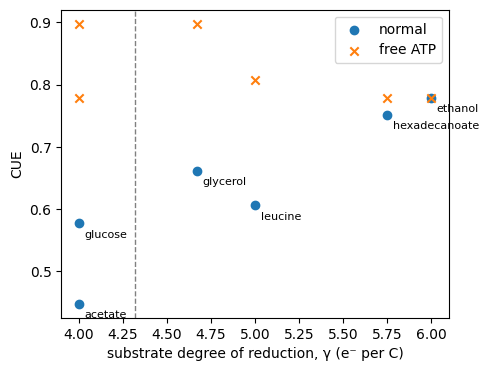

In [59]:
# Plot CUE
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(results["gamma"], results["cue_normal"], label="normal")
ax.scatter(results["gamma"], results["cue_free_atp"], marker="x", label="free ATP")
for _, row in results.iterrows():
    ax.annotate(row["substrate"], (row["gamma"], row["cue_normal"]),
                fontsize=8, xytext=(4, -10), textcoords="offset points")
ax.axvline(4.32, color="grey", linestyle="--", linewidth=1)   # biomass γ_X
ax.set_xlabel("substrate degree of reduction, γ (e⁻ per C)")
ax.set_ylabel("CUE")
ax.legend()

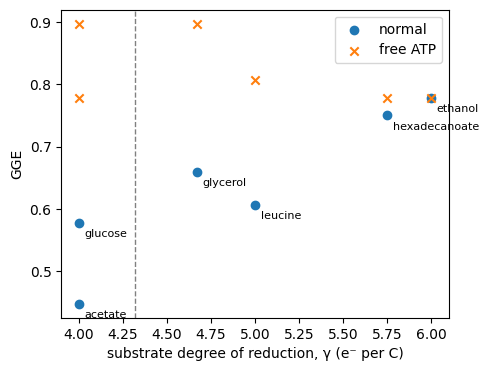

In [60]:
# Plot GGE
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(results["gamma"], results["gge_normal"], label="normal")
ax.scatter(results["gamma"], results["gge_free_atp"], marker="x", label="free ATP")
for _, row in results.iterrows():
    ax.annotate(row["substrate"], (row["gamma"], row["gge_normal"]),
                fontsize=8, xytext=(4, -10), textcoords="offset points")
ax.axvline(4.32, color="grey", linestyle="--", linewidth=1)   # biomass γ_X
ax.set_xlabel("substrate degree of reduction, γ (e⁻ per C)")
ax.set_ylabel("GGE")
ax.legend()

In [61]:
# Free NADH: NAD+ + H+ -> NADH, i.e. 2 electrons from nowhere
nad  = model.metabolites.get_by_id("cpd00003_c0")
nadh = model.metabolites.get_by_id("cpd00004_c0")
free_nadh = cobra.Reaction("FREE_NADH")
free_nadh.add_metabolites({nad: -1, h: -1, nadh: 1})
free_nadh.bounds = (0, 0)
model.add_reactions([free_nadh])

In [62]:
def titrate(ex_id, gamma_substrate, nadh_levels=(0, 10, 20, 30, 45, 60, 90, 120)):
    rows = []
    for x in nadh_levels:
        with model:
            model.reactions.FREE_NADH.bounds = (x, x)   # force exactly x mmol NADH in
            out = run_fba(ex_id)
        rows.append({"nadh": x,
                     "effective_gamma": gamma_substrate + 2 * x / CARBON_UPTAKE,
                     "cue": round(out["cue"], 3)})
    return pd.DataFrame(rows)

In [65]:
acetate_res = titrate("EX_cpd00029_e0", 4.0)   # acetate
glucose_res = titrate("EX_cpd00027_e0", 4.0)   # glucose

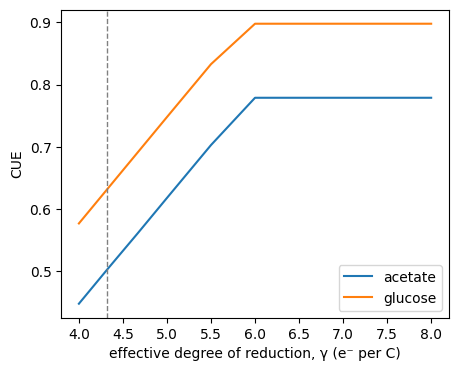

In [66]:
# Plot the results
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(acetate_res["effective_gamma"], acetate_res["cue"], label="acetate")
ax.plot(glucose_res["effective_gamma"], glucose_res["cue"], label="glucose")
ax.axvline(4.32, color="grey", linestyle="--", linewidth=1)   # biomass γ_X
ax.set_xlabel("effective degree of reduction, γ (e⁻ per C)")
ax.set_ylabel("CUE")
ax.legend()